# 02 - Cohort Analysis & Retention
**Question:** of the users who first appear in month *M*, how many are still active (any event) in month *M+k*?

- **Cohort** = calendar month of a user's first event in the data.
- **Retention(k)** = share of the cohort with >= 1 event in month M+k. Cells past the end of the data are blank (unobserved), not zero.
- **Caveat:** the first month in the data (Oct 2019) also contains *existing* customers whose real first visit was earlier, so that cohort looks better than a true new-user cohort.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import OUTPUTS
OUTPUTS.mkdir(exist_ok=True)
pd.options.display.float_format = "{:,.4f}".format
%matplotlib inline
from src.data_prep import load_processed
from src.cohort import cohort_retention, repeat_purchase_by_cohort
from src.plots import plot_retention_heatmap
users, activity, orders = load_processed()

In [2]:
sizes, counts, retention = cohort_retention(users, activity)
retention.to_csv(OUTPUTS / "retention_table.csv")
retention

months_since_first_visit,0,1,2,3,4
cohort,,,,,
2019-10,1.0000,0.1354,0.0915,0.0791,0.0683
2019-11,1.0000,0.1107,0.0690,0.0568,NaN
2019-12,1.0000,0.0925,0.0546,NaN,NaN
2020-01,1.0000,0.0991,NaN,NaN,NaN
2020-02,1.0000,NaN,NaN,NaN,NaN


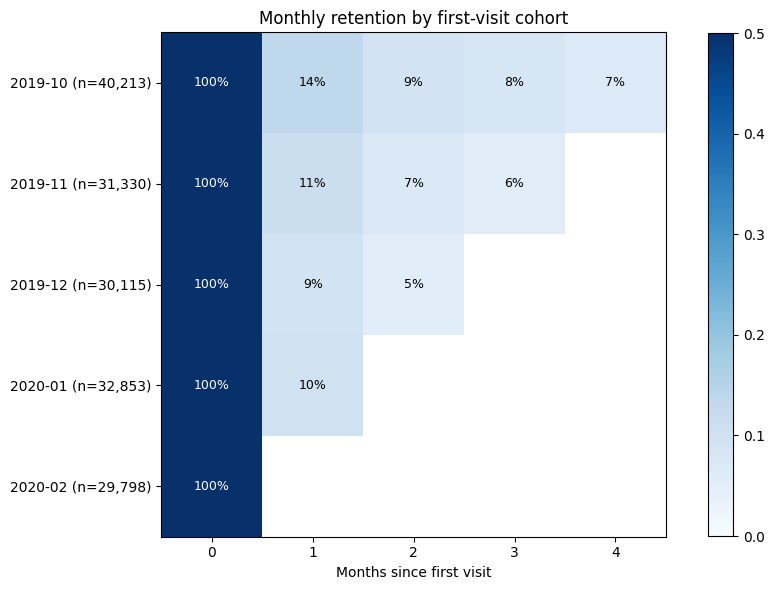

In [3]:
fig = plot_retention_heatmap(retention, sizes)
fig.savefig(OUTPUTS / "retention_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Average retention curve (weighted by cohort size, excluding the first, left-censored cohort)

,month_k,retention,cohorts_used
0,1,0.1008,3
1,2,0.0619,2
2,3,0.0568,1


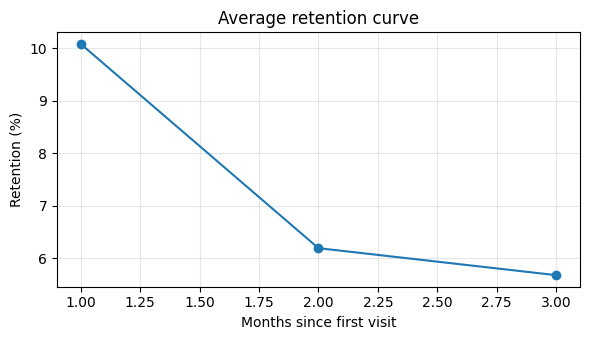

In [4]:
rows = []
for k in retention.columns[1:]:
    ok = retention[k].notna() & (retention.index != retention.index[0])
    if ok.any():
        rows.append({"month_k": k, "retention": counts.loc[ok, k].sum() / sizes[ok].sum(), "cohorts_used": int(ok.sum())})
curve = pd.DataFrame(rows)
display(curve)
if len(curve):
    plt.figure(figsize=(6, 3.5))
    plt.plot(curve["month_k"], curve["retention"] * 100, marker="o")
    plt.xlabel("Months since first visit"); plt.ylabel("Retention (%)"); plt.title("Average retention curve")
    plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(OUTPUTS / "retention_curve.png", dpi=150); plt.show()

## Purchase behaviour by cohort

In [5]:
repeat_purchase_by_cohort(users, orders)

,users,buyer_rate,repeat_rate_of_all,repeat_rate_of_buyers
cohort,,,,
2019-10,40213,0.0956,0.0304,0.3180
2019-11,31330,0.0791,0.0161,0.2030
2019-12,30115,0.0594,0.0090,0.1515
2020-01,32853,0.0527,0.0063,0.1191
2020-02,29798,0.0425,0.0027,0.0640
